**Quantum model**

This notebook builds the quantum counterpart of the classical model: a variational quantum classifier (VQC). It loads the exact same train/test splits saved by the classical notebook, so both models are compared on identical data. The circuit encodes the 4 features as rotation angles, applies trainable layers, and measures one qubit. The measured value is the model's output, and a classical optimizer tunes the circuit's parameters.

The circuit and training code live in `vqc.py` (shared with `Ablation.ipynb`); this notebook runs it and compares the result with the classical models. **Run `Classical.ipynb` first**, because it creates the `splits/` folder and `results/classical.json`.

In [1]:
import json, sys
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml

import vqc   # our circuit + training code

SPLITS = Path("splits")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEEDS = [0, 1, 2, 3, 4]

# Record the exact package versions used, so the run can be reproduced
versions = {"python": sys.version.split()[0]}
for pkg in ["numpy", "scikit-learn", "pandas", "matplotlib", "pennylane"]:
    try:
        versions[pkg] = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        versions[pkg] = "not installed"
(RESULTS / "environment.txt").write_text("\n".join(f"{k}=={v}" for k, v in versions.items()) + "\n")
print(versions)

{'python': '3.14.6', 'numpy': '2.5.5', 'scikit-learn': '1.9.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'pennylane': '0.45.1'}


## The model

- **Encoding (angle encoding):** each feature becomes the angle of an `RY` rotation on its own qubit, so 4 features need 4 qubits. `Classical.ipynb` already scaled every feature to [0, π]. On that range `RY` moves a qubit from |0⟩ towards |1⟩ without wrapping around, so different feature values always give different quantum states (a [0, 2π] range would map 0 and 2π to the same state).
- **Trainable layers:** `StronglyEntanglingLayers` with 3 layers. Each layer applies a general rotation (3 angles) to every qubit and then a ring of CNOT gates, so information from all 4 features can reach the measured qubit. 3 layers × 4 qubits × 3 angles = **36 trainable parameters**, deliberately close to the small MLP's 37, so the two models are the same size.
- **Read-out:** the expectation value ⟨Z⟩ of qubit 0, a number between −1 and +1. Positive means class 1, negative means class 0.
- **Training:** square loss between ⟨Z⟩ and the label mapped to ±1, minimised with full-batch Adam (learning rate 0.1, 100 steps) from a small random start. The learning rate, step count and initial scale were chosen using a validation slice of the *training* data only; the test sets were never used to tune anything.
- **Simulator:** exact statevector simulation (`default.qubit`), with no shot noise and no hardware noise, so a given seed always gives the same result.

0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
3: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     

M0 = 
[0.5819965  2.95252576 0.82091868 1.28663217]
M1 = 
[[[ 0.06286511 -0.06605243  0.32021133]
  [ 0.05245006 -0.26783469  0.18079753]
  [ 0.65200002  0.47354048 -0.35186762]
  [-0.63271074 -0.31163723  0.02066299]]

 [[-1.16251539 -0.10939583 -0.62295547]
  [-0.36613368 -0.27212949 -0.15815008]
  [ 0.20581527  0.52125668 -0.06426733]
  [ 0.68323174 -0.33259734  0.17575504]]

 [[ 0.45173509  0.04700615 -0.37174962]
  [-0.46086269 -0.22886291  0.11009756]
  [-0.50480909 -0.10458779 -0.0796125 ]
  [ 0.27042279  0.10732956  0.17768635]]]


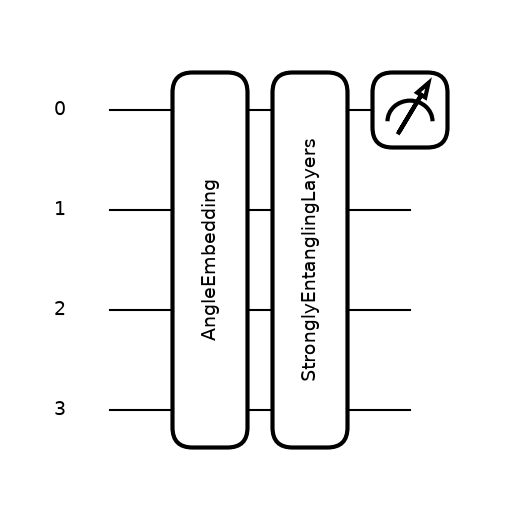

In [2]:
# Draw the circuit (random weights, just for the picture). Skipped gracefully if drawing is unavailable.
try:
    x_demo = np.load(SPLITS / "seed0.npz")["Xtr"][0]
    w_demo = 0.5 * np.random.default_rng(0).standard_normal((3, vqc.N_QUBITS, 3))
    circuit = vqc.make_circuit(n_layers=3)
    print(qml.draw(circuit)(x_demo, w_demo))
    fig, ax = qml.draw_mpl(circuit, decimals=2)(x_demo, w_demo)
    fig.savefig(RESULTS / "circuit.png", dpi=200, bbox_inches="tight")
except Exception as e:
    print("circuit drawing skipped:", e)

## Quick check on one split

Before running all 5 seeds, train once on seed 0. The training loss should fall steadily and the accuracies should land around 0.8.

{'seed': 0, 'train_acc': 0.795, 'test_acc': 0.82, 'fit_time_s': 2.310133457183838, 'n_params': 36}


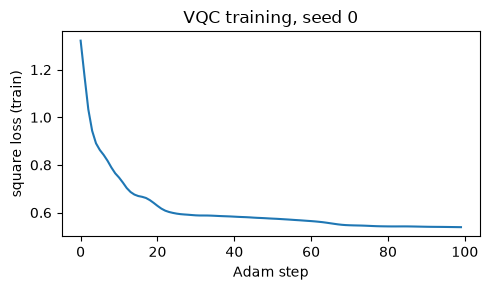

In [3]:
res0, losses0 = vqc.run_seed(0)
print(res0)

plt.figure(figsize=(5, 3))
plt.plot(losses0)
plt.xlabel("Adam step"); plt.ylabel("square loss (train)"); plt.title("VQC training, seed 0")
plt.tight_layout(); plt.show()

## Train and evaluate on all 5 splits

The results are saved to `results/quantum.json` in exactly the same format as `results/classical.json`.

seed 0: train 0.795   test 0.820   (2s)
seed 1: train 0.783   test 0.795   (2s)
seed 2: train 0.813   test 0.750   (2s)
seed 3: train 0.815   test 0.775   (2s)
seed 4: train 0.780   test 0.810   (2s)


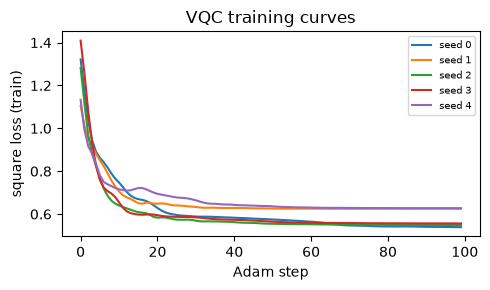

In [4]:
vqc_results, vqc_losses = [], {}
for seed in SEEDS:
    r, l = vqc.run_seed(seed)
    vqc_results.append(r)
    vqc_losses[seed] = l
    print(f"seed {seed}: train {r['train_acc']:.3f}   test {r['test_acc']:.3f}   ({r['fit_time_s']:.0f}s)")

with open(RESULTS / "quantum.json", "w") as f:
    json.dump({"vqc": vqc_results}, f, indent=2)
with open(RESULTS / "quantum_loss_curves.json", "w") as f:
    json.dump({str(k): v for k, v in vqc_losses.items()}, f)

plt.figure(figsize=(5, 3))
for seed, l in vqc_losses.items():
    plt.plot(l, label=f"seed {seed}")
plt.xlabel("Adam step"); plt.ylabel("square loss (train)"); plt.legend(fontsize=7)
plt.title("VQC training curves"); plt.tight_layout()
plt.savefig(RESULTS / "training_curves.png", dpi=200); plt.show()

## Quantum vs classical

All five models were trained on the same 5 splits and tested on the same test rows.

In [5]:
classical = json.load(open(RESULTS / "classical.json"))
quantum = json.load(open(RESULTS / "quantum.json"))
all_runs = {**classical, **quantum}

rows = [{"model": name, **r} for name, runs in all_runs.items() for r in runs]
res = pd.DataFrame(rows)

summary = res.groupby("model").agg(
    test_mean=("test_acc", "mean"),
    test_std=("test_acc", "std"),
    train_mean=("train_acc", "mean"),
    time_mean_s=("fit_time_s", "mean"),
    n_params=("n_params", "first"),
).round(3)
summary["train_test_gap"] = (summary.train_mean - summary.test_mean).round(3)
summary = summary.sort_values("test_mean", ascending=False)
summary.to_csv(RESULTS / "summary.csv")
summary

,test_mean,test_std,train_mean,time_mean_s,n_params,train_test_gap
model,,,,,,
svm_rbf,0.818,0.020,0.879,0.631,NaN,0.061
mlp_large,0.811,0.041,0.860,1.827,1249.0,0.049
logreg,0.800,0.015,0.814,0.010,5.0,0.014
mlp_small,0.795,0.029,0.799,0.704,37.0,0.004
vqc,0.790,0.028,0.797,2.136,36.0,0.007


In [6]:
# Paired comparison: VQC minus each other model, split by split (same data, so this is the fair comparison)
vqc_test = res[res.model == "vqc"].set_index("seed")["test_acc"]
rows = []
for name in all_runs:
    if name == "vqc":
        continue
    d = vqc_test - res[res.model == name].set_index("seed")["test_acc"]
    rows.append({"model": name, "mean_diff": d.mean(), "std_diff": d.std(), "splits_where_vqc_better": int((d > 0).sum())})
print("VQC test accuracy minus the other model (positive = VQC better):")
display(pd.DataFrame(rows).set_index("model").round(3))

# How much does one 200-row test set wobble just by chance?
n_test = len(np.load(SPLITS / "seed0.npz")["yte"])
p = res.test_acc.mean()
print(f"Sampling noise of a single test accuracy: about +/-{100 * np.sqrt(p * (1 - p) / n_test):.1f} points (n_test = {n_test})")

VQC test accuracy minus the other model (positive = VQC better):


,mean_diff,std_diff,splits_where_vqc_better
model,,,
logreg,-0.010,0.022,1
svm_rbf,-0.028,0.038,1
mlp_small,-0.005,0.012,2
mlp_large,-0.021,0.039,1


Sampling noise of a single test accuracy: about +/-2.8 points (n_test = 200)


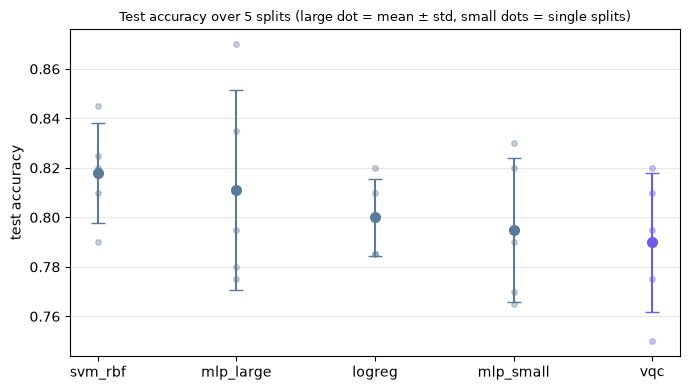

| model | test acc (mean ± std) | train acc | fit time (s) | params |
|---|---|---|---|---|
| svm_rbf | 0.818 ± 0.020 | 0.879 | 0.63 | - |
| mlp_large | 0.811 ± 0.041 | 0.860 | 1.83 | 1249 |
| logreg | 0.800 ± 0.015 | 0.814 | 0.01 | 5 |
| mlp_small | 0.795 ± 0.029 | 0.799 | 0.70 | 37 |
| vqc | 0.790 ± 0.028 | 0.797 | 2.14 | 36 |


In [7]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(7, 4))
for i, m in enumerate(order):
    pts = res[res.model == m].test_acc
    colour = "#6d5ce7" if m == "vqc" else "#5b7a99"
    ax.scatter([i] * len(pts), pts, color=colour, alpha=0.35, s=16, zorder=2)
    ax.errorbar(i, pts.mean(), yerr=pts.std(), fmt="o", color=colour, capsize=5, markersize=7, zorder=3)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("test accuracy")
ax.set_title("Test accuracy over 5 splits (large dot = mean ± std, small dots = single splits)", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); fig.savefig(RESULTS / "comparison.png", dpi=200); plt.show()

# Markdown table for the README / report
lines = ["| model | test acc (mean ± std) | train acc | fit time (s) | params |", "|---|---|---|---|---|"]
for name, r in summary.iterrows():
    params = "-" if pd.isna(r.n_params) else int(r.n_params)
    lines.append(f"| {name} | {r.test_mean:.3f} ± {r.test_std:.3f} | {r.train_mean:.3f} | {r.time_mean_s:.2f} | {params} |")
(RESULTS / "summary.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

## How to read these results

- Every model was trained and tested on the same 5 splits, so the paired differences compare like with like.
- A single 200-row test set wobbles by roughly ±3 accuracy points just by chance (printed above). A difference smaller than that is not evidence that one model is better.
- Tuning effort is not identical: only the SVM was tuned (5-fold cross-validation on the training set); logistic regression and the MLPs use scikit-learn defaults, and the VQC's learning rate, step count and initial scale were fixed once using a validation slice of the training data.
- Everything ran on an ideal, noise-free simulator with 4 qubits and 800 rows of one dataset. These results say nothing about real quantum hardware or much larger problems.
- If you change `lr` or `steps`, judge the change by the *training* loss or a validation split, never by test accuracy.